<a href="https://colab.research.google.com/github/foner21/AISE4010_Section4_Group5/blob/main/AISE4010_Section4Group5_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AISE 4010 — Room Occupancy Estimation

**Labs 1–2 + Stage 1 preparation (traditional baselines, MLP, CNN, grid search)**

**Group:** 5
**Members:** Fiona Oner, Stephanie Ndefo, Rebecca Fry, Aala Hamza
**Dataset:** [UCI Room Occupancy Estimation (#15)](https://archive.ics.uci.edu/dataset/864/room+occupancy+estimation)


In [1]:
%pip -q install pandas numpy matplotlib seaborn scikit-learn tensorflow joblib

In [2]:
import os, io, zipfile, urllib.request, warnings, time, random, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED)
EXPECTED_FREQ = pd.Timedelta(seconds=30)
LOOKBACK = 20
HORIZON = 2
TARGET = 'Room_Occupancy_Count'
RUN_DEEP_MODELS = True  # change to False to complete Labs 1-2 faster
RUN_GRID_SEARCH = True  # grid-search one of the Stage 1 neural models
RUN_FINAL_TEST = False  # do not change without TA permission/final protocol
DATA_DIR = Path('data'); DATA_DIR.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid')
print('Working directory:', Path.cwd())

Working directory: /content


In [3]:
# Download official UCI archive, extract the occupancy CSV, otherwise prompt for upload.
csv_path = DATA_DIR / 'Occupancy_Estimation.csv'
uci_archive = 'https://archive.ics.uci.edu/static/public/864/room+occupancy+estimation.zip'
if not csv_path.exists():
    try:
        request = urllib.request.Request(uci_archive, headers={'User-Agent': 'Mozilla/5.0'})
        with urllib.request.urlopen(request, timeout=45) as response:
            archive_bytes = response.read()
        with zipfile.ZipFile(io.BytesIO(archive_bytes)) as archive:
            names = [name for name in archive.namelist() if name.lower().endswith('.csv') and not name.startswith('__MACOSX')]
            print('CSV members in archive:', names)
            candidates = [name for name in names if 'occupancy' in name.lower()]
            if not candidates: raise ValueError('Expected occupancy CSV not found in downloaded zip')
            with archive.open(candidates[0]) as src:
                csv_path.write_bytes(src.read())
        print('Dataset saved to:', csv_path)
    except Exception as exc:
        print('Automatic download failed:', repr(exc))
        print('Download the CSV from the UCI dataset page and upload it in the prompt.')
        try:
            from google.colab import files
            uploaded = files.upload()
            csv_candidates = [(name, contents) for name, contents in uploaded.items() if name.lower().endswith('.csv')]
            if not csv_candidates: raise RuntimeError('Please upload a CSV file, then rerun this cell.')
            csv_path.write_bytes(csv_candidates[0][1])
        except ImportError:
            raise RuntimeError('Place Occupancy_Estimation.csv in the local data/ folder.') from exc
assert csv_path.exists(), 'Dataset file still missing'
print('Bytes:', csv_path.stat().st_size)

CSV members in archive: ['Occupancy_Estimation.csv']
Dataset saved to: data/Occupancy_Estimation.csv
Bytes: 931630


## 1. Problem definition (Lab 1)
**Objective:** predict the **number of people in the room** (`Room_Occupancy_Count`) using historical sensor measurements, historical occupancy labels and known-in-advance calendar variables. Target unit: *people* (integer class), so this is multi-class classification rather than continuous regression.

**Native frequency:** expected 30 seconds, verified below. **Resampling rule:** no resampling in the initial pipeline to preserve short occupancy transitions. **Lookback:** 20 records (10 minutes). **Forecast horizon:** 2 records (1 minute after the latest input measurement).

**Operational application:** anticipate occupancy for building HVAC/ventilation and lighting management. **Leakage policy:** future sensor measurements and future true occupancy labels cannot appear in model features; preprocessing is fitted on training data only. Long timestamp gaps are not bridged in temporal windows.

**Limitations:** extremely short observation period and potential class shifts across chronological partitions. Any candidate CO₂ slope using future observations is excluded; a strictly past-only derived slope can be added in future experiments.

In [4]:
#establishing the number of observations, columns and occupancy classes
raw = pd.read_csv(csv_path)
raw.columns = raw.columns.str.strip()
print('Shape:', raw.shape)
print('Columns:', raw.columns.tolist())
display(raw.head(8))
print('\nDtypes:'); display(raw.dtypes.to_frame('dtype'))
required = {'Date', 'Time', TARGET}
assert required.issubset(raw.columns), f'Missing expected columns: {required - set(raw.columns)}'
raw['timestamp'] = pd.to_datetime(raw['Date'].astype(str) + ' ' + raw['Time'].astype(str), errors='coerce')
invalid_ts = int(raw['timestamp'].isna().sum())
if invalid_ts: print(f'WARNING: {invalid_ts} unparseable timestamps; these rows will be excluded after audit.')
df = raw.dropna(subset=['timestamp']).sort_values('timestamp').set_index('timestamp')
assert df.index.is_monotonic_increasing

Shape: (10129, 19)
Columns: ['Date', 'Time', 'S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S5_CO2_Slope', 'S6_PIR', 'S7_PIR', 'Room_Occupancy_Count']


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count
0,2017/12/22,10:49:41,24.94,24.75,24.56,25.38,121,34,53,40,0.08,0.19,0.06,0.06,390,0.769231,0,0,1
1,2017/12/22,10:50:12,24.94,24.75,24.56,25.44,121,33,53,40,0.93,0.05,0.06,0.06,390,0.646154,0,0,1
2,2017/12/22,10:50:42,25.00,24.75,24.50,25.44,121,34,53,40,0.43,0.11,0.08,0.06,390,0.519231,0,0,1
3,2017/12/22,10:51:13,25.00,24.75,24.56,25.44,121,34,53,40,0.41,0.10,0.10,0.09,390,0.388462,0,0,1
4,2017/12/22,10:51:44,25.00,24.75,24.56,25.44,121,34,54,40,0.18,0.06,0.06,0.06,390,0.253846,0,0,1
5,2017/12/22,10:52:14,25.00,24.81,24.56,25.44,121,34,54,40,0.13,0.06,0.06,0.07,390,0.165385,0,0,1
6,2017/12/22,10:52:45,25.00,24.75,24.56,25.44,120,34,54,40,1.39,0.32,0.43,0.06,390,0.076923,1,0,1
7,2017/12/22,10:53:15,25.00,24.81,24.56,25.44,121,34,54,41,0.09,0.06,0.09,0.05,390,-0.011538,0,0,1



Dtypes:


,dtype
Date,object
Time,object
S1_Temp,float64
S2_Temp,float64
S3_Temp,float64
S4_Temp,float64
S1_Light,int64
S2_Light,int64
S3_Light,int64
S4_Light,int64


S1-temp- s4-temp is the temperature measurements from four sensors

s1-light -s4 light: light measurements from four sensors

s1-sound and s4-sound : sound measurements from four sensors

s5_Co2: CO2 measurements

s5_ Co2 : a derived measure of CO2 change

s6_PIR s7_PIR : passive infrafred motion detection

Room_Occupancy_ count : number of occupants
where the target classes are 0,1,2 and 3 people.

## The main objective
predicting the future number of room occupants using a multivariate time series. Using a lookback of 20 observations, approximately 10 minutes of historical sensor and occupancy data, to predict the occupancy count two observations ahead, which is about one minute into the future.

## 2. Timestamp audit — Lecture 1 and Lecture 2

first timestamp was recorded on december 22,2017 at 10:49 AM and the last timestamp on january 11th 2018 at 9:00 AM.

most common interval 31 seconds (6373 instances )

with no missing record values and duplicate timestamps. There were however missing time periods. This is accounted for in section 6 where we defined the maximum interval which allows the normal 30-31 second intervals while rejecting any prediction window that crosses an interval longer than 35 seconds.

largest gap was 15 days , 6hours, 15 minutes and 47 seconds.


In [5]:
diffs = df.index.to_series().diff()
gap_mask = diffs > EXPECTED_FREQ
gaps = diffs.loc[gap_mask]
dup_count = int(df.index.duplicated().sum())
na_cols = df.isna().sum()
audit = pd.DataFrame([
    ['Source', 'UCI Room Occupancy Estimation, dataset #15'],
    ['Target', TARGET], ['Target unit', 'people (class label)'],
    ['Expected native frequency', '30 seconds — verify with observed intervals'],
    ['Observed most common interval', str(diffs.mode().iloc[0]) if not diffs.mode().empty else 'N/A'],
    ['Coverage start', str(df.index.min())], ['Coverage end', str(df.index.max())],
    ['Rows', len(df)], ['Unparseable date/time rows', invalid_ts],
    ['Duplicate timestamps', dup_count], ['Intervals exceeding 30 s', len(gaps)],
    ['Largest gap', str(gaps.max()) if len(gaps) else 'None'],
    ['Missing table cells', int(df.isna().sum().sum())],
], columns=['Field', 'Result'])
display(audit)
print('TOP OBSERVED TIME INTERVALS:'); display(diffs.value_counts().head(12).rename_axis('interval').to_frame('count'))
print('LARGEST GAPS:'); display(gaps.nlargest(10).to_frame('gap_duration'))
na_summary = pd.DataFrame({'missing_count': df.isna().sum(), 'missing_pct': (100 * df.isna().mean()).round(3)})
print('MISSINGNESS:'); display(na_summary)
print('DUPLICATES:', dup_count)

,Field,Result
0,Source,"UCI Room Occupancy Estimation, dataset #15"
1,Target,Room_Occupancy_Count
2,Target unit,people (class label)
3,Expected native frequency,30 seconds — verify with observed intervals
4,Observed most common interval,0 days 00:00:31
5,Coverage start,2017-12-22 10:49:41
6,Coverage end,2018-01-11 09:00:09
7,Rows,10129
8,Unparseable date/time rows,0
9,Duplicate timestamps,0


TOP OBSERVED TIME INTERVALS:


,count
interval,
0 days 00:00:31,6373
0 days 00:00:30,3614
0 days 00:01:01,131
0 days 00:02:34,2
0 days 00:01:02,2
0 days 00:01:32,1
0 days 00:25:32,1
0 days 00:03:35,1
0 days 00:03:04,1


LARGEST GAPS:


,gap_duration
timestamp,
2018-01-10 15:25:48,15 days 06:15:47
2017-12-25 09:11:42,1 days 00:00:52
2017-12-22 13:08:03,0 days 00:25:32
2017-12-22 19:35:35,0 days 00:03:35
2017-12-22 19:39:40,0 days 00:03:04
2017-12-22 11:39:13,0 days 00:02:34
2017-12-23 16:40:18,0 days 00:02:34
2017-12-22 15:25:24,0 days 00:01:32
2017-12-24 00:00:56,0 days 00:01:02


MISSINGNESS:


,missing_count,missing_pct
Date,0,0.0
Time,0,0.0
S1_Temp,0,0.0
S2_Temp,0,0.0
S3_Temp,0,0.0
S4_Temp,0,0.0
S1_Light,0,0.0
S2_Light,0,0.0
S3_Light,0,0.0
S4_Light,0,0.0


DUPLICATES: 0


In [6]:
# Duplicate times are not averaged silently. We keep first row only after the audit,

if dup_count:
    print(f'Cleaning note: dropping {dup_count} repeated timestamps (keeping first).')
    df = df.loc[~df.index.duplicated(keep='first')].copy()
else:
    df = df.copy()

# Convert numeric sensor/label fields while keeping Date/Time out of the feature matrix.
for col in df.columns.difference(['Date', 'Time']):
    df[col] = pd.to_numeric(df[col], errors='coerce')
print('Target missing rows:', df[TARGET].isna().sum())
# Target rows cannot be reliably imputed in supervised forecasting.
df = df.dropna(subset=[TARGET]).copy()
df[TARGET] = df[TARGET].astype(int)
print('Post-audit rows:', len(df))

Target missing rows: 0
Post-audit rows: 10129


## 3. Exploratory data analysis (Lab 1)
**Figure 1:** target class distribution. **Figure 2:** observed occupancy across the measured interval. **Figure 3:** CO₂ versus time, coloured by occupant count. **Figure 4:** per-sensor distribution by class.

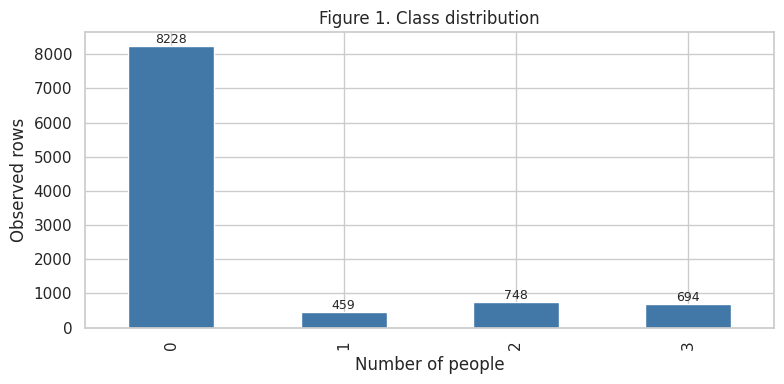

,count,percent
Room_Occupancy_Count,,
0,8228,81.23
1,459,4.53
2,748,7.38
3,694,6.85


In [7]:
fig, ax = plt.subplots(figsize=(8,4))
counts = df[TARGET].value_counts().sort_index()
counts.plot.bar(ax=ax, color='#4278a8')
ax.set(xlabel='Number of people', ylabel='Observed rows', title='Figure 1. Class distribution')
for i, value in enumerate(counts): ax.text(i, value, str(value), ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()
display(pd.DataFrame({'count':counts, 'percent':(100*counts/counts.sum()).round(2)}))

Figure 1 highlighted the class imbalance where 80% of the recorded observations were in class 0. This can lead to poor generalization down the line where the model could achieve high accuracy by predicting an empty room. Relying on accuracy alone is therefore not possible and therefore macro-f1 and balanced accuracy.

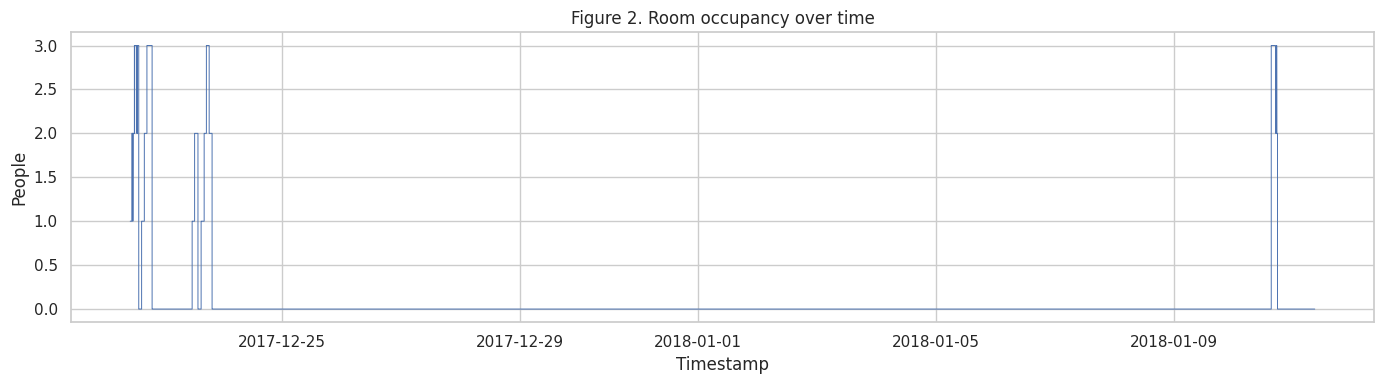

In [8]:
fig, ax = plt.subplots(figsize=(14,4))
ax.step(df.index, df[TARGET], where='post', linewidth=0.7)
ax.set(title='Figure 2. Room occupancy over time', ylabel='People', xlabel='Timestamp')
plt.tight_layout(); plt.show()

Figure 2: this further shows the class imbalance and the class distribution over the years.



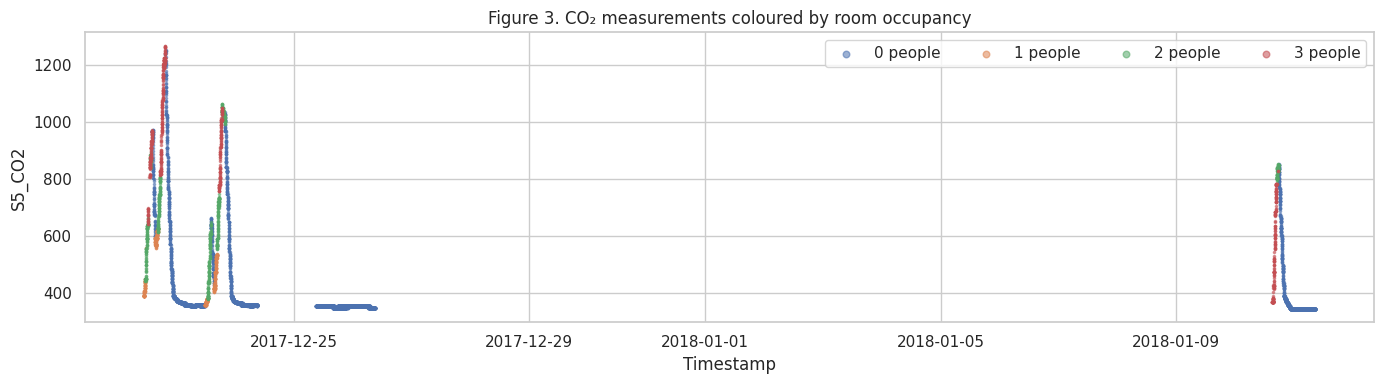

In [9]:
co2_candidates = [c for c in df.columns if c.lower() in ['s5_co2', 'co2']]
if co2_candidates:
    co2_col = co2_candidates[0]
    fig, ax = plt.subplots(figsize=(14,4))
    classes = sorted(df[TARGET].unique())
    for label in classes:
        part = df[df[TARGET] == label]
        ax.scatter(part.index, part[co2_col], s=2.5, alpha=0.55, label=f'{label} people')
    ax.set(title='Figure 3. CO₂ measurements coloured by room occupancy', xlabel='Timestamp', ylabel=co2_col)
    ax.legend(markerscale=3, ncol=min(5,len(classes)))
    plt.tight_layout(); plt.show()
else: print('CO₂ field not found. Available columns:',df.columns.tolist())

Comparing this chart with figure 2 shows the correlation between Co2 measurements and room occupancy. (they are directly proportional to one another )

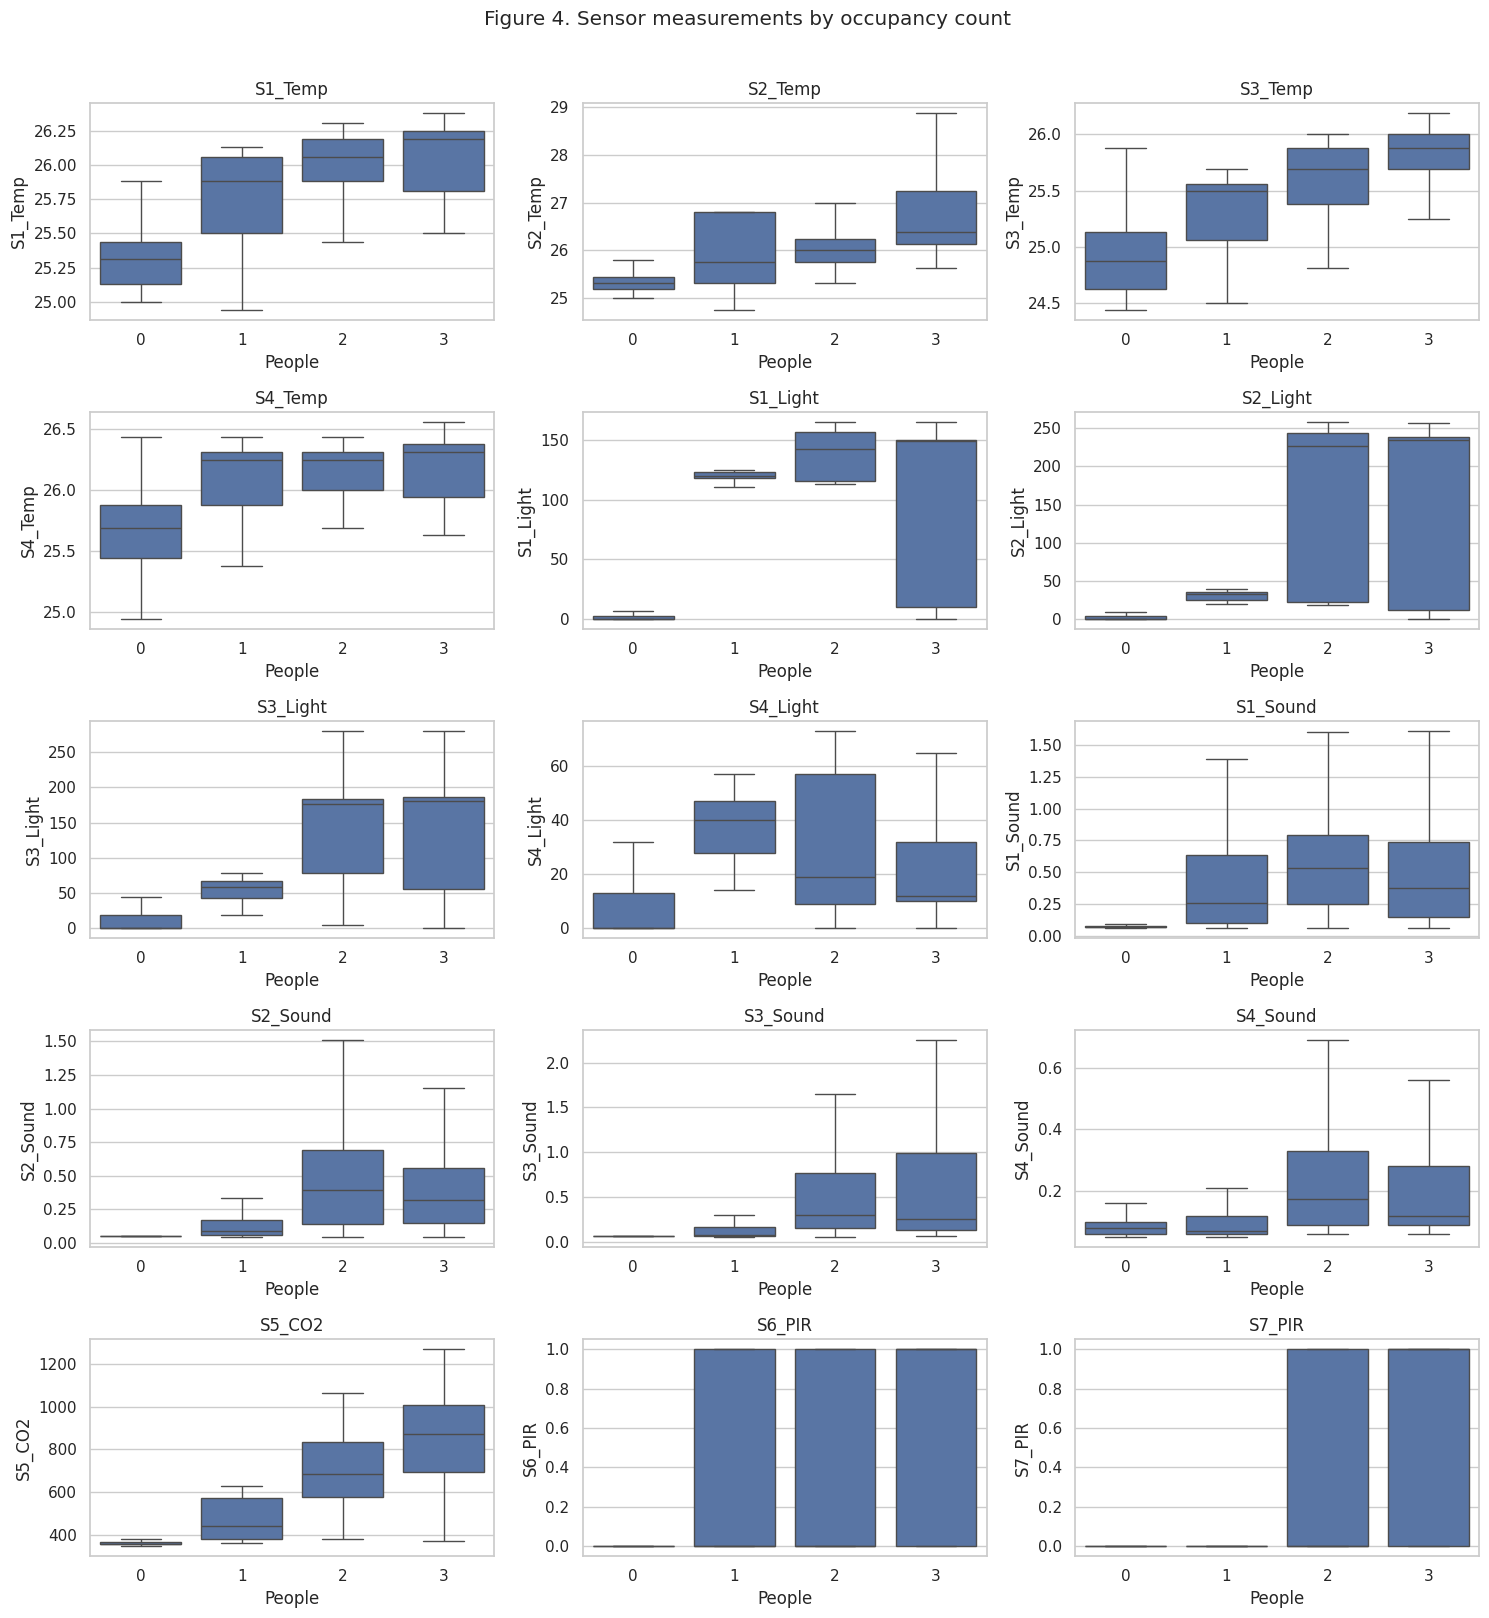

In [10]:
sensor_cols = df.select_dtypes(include='number').columns.drop(TARGET).tolist()
# CO2 slope may be defined using future sensor points; retain for audit only, never as model input.
plot_cols = [c for c in sensor_cols if 'slope' not in c.lower()]
if plot_cols:
    ncols = 3
    nrows = (len(plot_cols)+ncols-1)//ncols
    fig, axes = plt.subplots(nrows,ncols,figsize=(15,3.2*nrows),squeeze=False)
    for ax, sensor in zip(axes.flat,plot_cols):
        sns.boxplot(data=df,x=TARGET,y=sensor,ax=ax,showfliers=False)
        ax.set_title(sensor); ax.set_xlabel('People')
    for ax in axes.flat[len(plot_cols):]: ax.axis('off')
    fig.suptitle('Figure 4. Sensor measurements by occupancy count', y=1.01)
    plt.tight_layout(); plt.show()



Sensor s5_CO2 appears to be one of the strongest class-separating sensors because its median values increase with increase in occupancy.
S3_ temp behaves similarly.
 S4_temp and S4_sound show considerable overlap between occupancy classes which indicates weaker individual separation.

 These associations alone may not have caused the differences for example Co2 levels can also depend on ventilation and recent occupancy history.

## 4. Chronological split and gap diagnostics (Lab 2)
No shuffling. We split before fitting preprocessors or constructing windows. Check class coverage: the brief period of available data can yield splits without all occupant counts.

,split,rows,start,end,classes,missing_classes
0,train,6077,2017-12-22 10:49:41,2017-12-25 15:51:29,"{0: 4470, 1: 459, 2: 655, 3: 493}",[]
1,validation,2026,2017-12-25 15:51:59,2018-01-10 15:34:59,"{0: 2007, 3: 19}","[np.int64(1), np.int64(2)]"
2,test (sealed),2026,2018-01-10 15:35:30,2018-01-11 09:00:09,"{0: 1751, 2: 93, 3: 182}",[np.int64(1)]


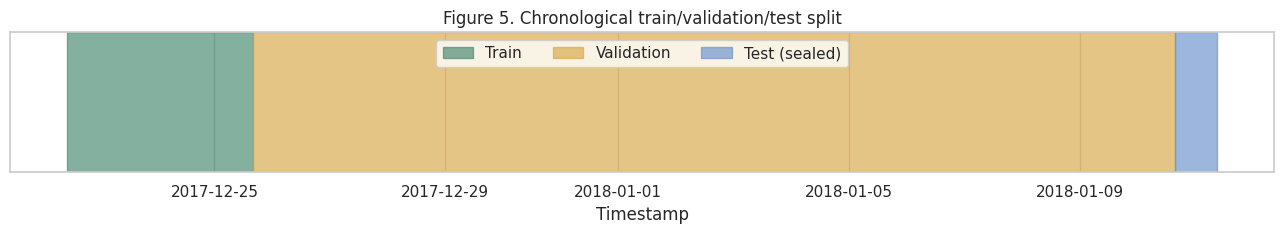

In [11]:
n = len(df); train_end = int(n*0.6); val_end = int(n*0.8)
train_df = df.iloc[:train_end].copy()
val_df   = df.iloc[train_end:val_end].copy()
test_df  = df.iloc[val_end:].copy()
all_classes = sorted(df[TARGET].unique())
summary=[]
for name, part in [('train',train_df),('validation',val_df),('test (sealed)',test_df)]:
    summary.append({'split':name,'rows':len(part),'start':part.index.min(),'end':part.index.max(),
                    'classes':str(part[TARGET].value_counts().sort_index().to_dict()),
                    'missing_classes':str(sorted(set(all_classes)-set(part[TARGET].unique())))})
display(pd.DataFrame(summary))
fig, ax=plt.subplots(figsize=(13,2.5))
for name, part, color in [('Train',train_df,'#43866e'),('Validation',val_df,'#d8a645'),('Test (sealed)',test_df,'#688fcb')]:
    ax.axvspan(part.index[0],part.index[-1],color=color,alpha=.65,label=name)
ax.set_yticks([]);ax.set_xlabel('Timestamp');ax.set_title('Figure 5. Chronological train/validation/test split')
ax.legend(loc='upper center',ncol=3);plt.tight_layout();plt.show()

**Split interpretation:** we divided the dataset into 3 parts using the 60/20/20 rule.
trianing- learning relationships and model parameters
validation- evaluating and comparing the models during development

test- final, independent evaluation.

we didn't use a random split to reduce the risk of data leakage and thus making sure the model learns from past data. An issue came up when there were no validation observations for classes 1 and 2 people. We plan to

**CO₂ slope leakage decision:** The supplied `S5_CO2_Slope` may have been calculated from measurements whose temporal support is not documented in the course handout. For safety, exclude **every column containing `slope`** unless its past-only definition can be established. If recreating, use `(CO2[t] - CO2[t-1]) / 30s`, never a centered difference or future CO₂.

Room_Occupancy_Count,0,1,2,3
row_0,,,,
2017-12-22,637,205,257,363
2017-12-23,1997,254,398,130
2017-12-24,1064,0,0,0
2017-12-25,1716,0,0,0
2017-12-26,1063,0,0,0
2018-01-10,0,0,0,19


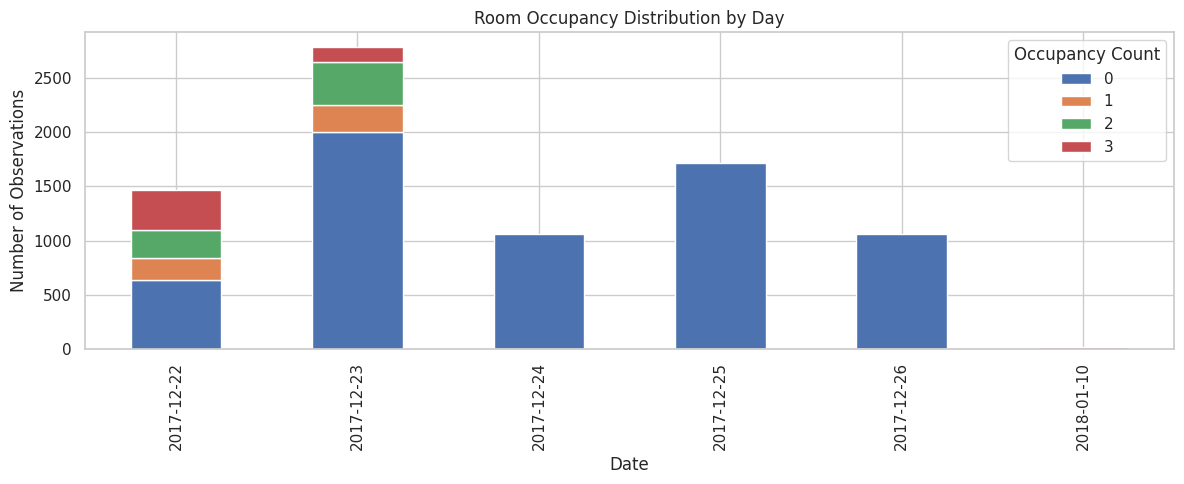

In [12]:
# investigating where class 1 and 2 instances occur to tweak training and validation periods
# Examine occupancy distribution by day
# Use development data only; leave test untouched

development_df = pd.concat([train_df, val_df])

daily_counts = pd.crosstab(
    development_df.index.date,
    development_df[TARGET]
)

daily_counts = daily_counts.reindex(
    columns=all_classes,
    fill_value=0
)

display(daily_counts)

daily_counts.plot(
    kind='bar',
    stacked=True,
    figsize=(12, 5)
)

plt.title('Room Occupancy Distribution by Day')
plt.xlabel('Date')
plt.ylabel('Number of Observations')
plt.legend(title='Occupancy Count')
plt.tight_layout()
plt.show()


In [13]:

# Screen chronological split candidates using only 80 % of the original dataset
# Valid forecast windows are connected
# The final 20% remains completely untouched

development_df = df.iloc[:int(len(df) * 0.80)].copy()
MAX_INTERVAL = pd.Timedelta(seconds=35)

def count_valid_targets(frame):
    counts = frame[TARGET].to_numpy()
    times = frame.index

    # A gap separates two recording segments
    breaks = (
        (times.to_series().diff() > MAX_INTERVAL) |
        (times.to_series().diff() <= pd.Timedelta(0))
    ).fillna(False).to_numpy()

    segment_id = np.cumsum(breaks)
    labels = []

    for i in range(LOOKBACK, len(frame) - HORIZON + 1):
        start = i - LOOKBACK
        target_pos = i + HORIZON - 1

        if segment_id[start] != segment_id[target_pos]:
            continue

        labels.append(counts[target_pos])

    return pd.Series(labels).value_counts().to_dict()


results = []

n_dev = len(development_df)

for train_fraction in np.arange(0.30, 0.71, 0.05):
    for val_fraction in [0.10, 0.15, 0.20, 0.25]:

        train_end = int(n_dev * train_fraction)
        val_end = int(n_dev * (train_fraction + val_fraction))

        if val_end > n_dev:
            continue

        candidate_train = development_df.iloc[:train_end]
        candidate_val = development_df.iloc[train_end:val_end]

        train_counts = count_valid_targets(candidate_train)
        val_counts = count_valid_targets(candidate_val)

        results.append({
            'Train % of development': round(train_fraction * 100),
            'Val % of development': round(val_fraction * 100),
            'Train end': candidate_train.index[-1],
            'Val end': candidate_val.index[-1],
            'Train classes': sorted(train_counts),
            'Val classes': sorted(val_counts),
            'Number of val classes': len(val_counts),
            'Val windows': sum(val_counts.values()),
            'Val class counts': val_counts
        })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values(
        ['Number of val classes', 'Val windows'],
        ascending=[False, False]
    ).head(15)
)


,Train % of development,Val % of development,Train end,Val end,Train classes,Val classes,Number of val classes,Val windows,Val class counts
11,40,25,2017-12-23 15:20:39,2017-12-24 08:50:55,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1470,"{0: 1106, 2: 179, 1: 94, 3: 91}"
3,30,25,2017-12-23 08:21:27,2017-12-24 01:51:43,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1459,"{0: 905, 2: 280, 1: 183, 3: 91}"
7,35,25,2017-12-23 11:50:48,2017-12-24 05:21:04,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1443,"{0: 899, 2: 280, 1: 173, 3: 91}"
10,40,20,2017-12-23 15:20:39,2017-12-24 05:21:04,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1172,"{0: 808, 2: 179, 1: 94, 3: 91}"
2,30,20,2017-12-23 08:21:27,2017-12-23 22:21:22,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1162,"{0: 608, 2: 280, 1: 183, 3: 91}"
6,35,20,2017-12-23 11:50:48,2017-12-24 01:51:43,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,1137,"{0: 593, 2: 280, 1: 173, 3: 91}"
9,40,15,2017-12-23 15:20:39,2017-12-24 01:51:43,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,866,"{0: 502, 2: 179, 1: 94, 3: 91}"
1,30,15,2017-12-23 08:21:27,2017-12-23 18:52:01,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,862,"{0: 403, 2: 185, 1: 183, 3: 91}"
5,35,15,2017-12-23 11:50:48,2017-12-23 22:21:22,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,840,"{0: 296, 2: 280, 1: 173, 3: 91}"
8,40,10,2017-12-23 15:20:39,2017-12-23 22:21:22,"[0, 1, 2, 3]","[0, 1, 2, 3]",4,569,"{0: 205, 2: 179, 1: 94, 3: 91}"


In [14]:

# Proposed changes to the dataset split
# expressed as fractions of development_df

TRAIN_FRACTION = 0.50
VAL_FRACTION = 0.20

n_dev = len(development_df)

train_end = int(n_dev * TRAIN_FRACTION)
val_end = int(n_dev * (TRAIN_FRACTION + VAL_FRACTION))

train_df = development_df.iloc[:train_end].copy()
val_df = development_df.iloc[train_end:val_end].copy()

# Preserve the original final 20% as test
test_df = df.iloc[int(len(df) * 0.80):].copy()

print("Training classes:",
      train_df[TARGET].value_counts().sort_index())

print("\nValidation classes:",
      val_df[TARGET].value_counts().sort_index())


Training classes: Room_Occupancy_Count
0    2444
1     459
2     655
3     493
Name: count, dtype: int64

Validation classes: Room_Occupancy_Count
0    1621
Name: count, dtype: int64


## 5. Train-only preprocessing (Lab 2)
We retain the native frequency. Calendar features represent known-in-advance values for the **input timestamps**. A median imputer and standard scaler are fitted on training *only* and applied unchanged to validation/test.

generating imputed/scaled frames is not the same as making forecasting windows; the windows below will reject any missing or irregular timestamp jump across their entire lookback-to-target interval.

s5_co2-slope is dropped because it cannot be verified from past data only.

In [15]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

safe_sensor_cols = [c for c in sensor_cols if 'slope' not in c.lower()]
assert TARGET not in safe_sensor_cols

def add_calendar(part):
    part = part.copy()
    clock = part.index.hour + part.index.minute/60 + part.index.second/3600
    day = part.index.dayofweek
    part['hour_sin'] = np.sin(2*np.pi*clock/24)
    part['hour_cos'] = np.cos(2*np.pi*clock/24)
    part['dow_sin'] = np.sin(2*np.pi*day/7)
    part['dow_cos'] = np.cos(2*np.pi*day/7)
    return part

train_df = add_calendar(train_df); val_df = add_calendar(val_df); test_df = add_calendar(test_df)
calendar_cols=['hour_sin','hour_cos','dow_sin','dow_cos']
feature_cols = safe_sensor_cols + calendar_cols
# imputation to deal with missing feature values as a safeguard. does not replace the missing time intervals
imputer = SimpleImputer(strategy='median', keep_empty_features=True)
#Standard scaler is needed because the input features have different numerical ranges
# Reduces the dominance of larger numerical scales
#This is done only on the training set to prevent future validation statistics from defining preprocessing.
scaler = StandardScaler()
X_train_rows = scaler.fit_transform(imputer.fit_transform(train_df[feature_cols]))
X_val_rows   = scaler.transform(imputer.transform(val_df[feature_cols]))
# Sealed: transform test features if needed for final stage, but do not score them.
print('Number of lagged sensor+calendar features:',len(feature_cols))
print('Feature names:',feature_cols)
print('Train feature matrix shape:',X_train_rows.shape)

Number of lagged sensor+calendar features: 19
Feature names: ['S1_Temp', 'S2_Temp', 'S3_Temp', 'S4_Temp', 'S1_Light', 'S2_Light', 'S3_Light', 'S4_Light', 'S1_Sound', 'S2_Sound', 'S3_Sound', 'S4_Sound', 'S5_CO2', 'S6_PIR', 'S7_PIR', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos']
Train feature matrix shape: (4051, 19)


## 6. Sliding-window / lag method — Lecture 3, pages 23–27

4279 samples, 20 timesteps, 20 features

output array has one future class label associated with each window.

29% of possible training windows were exluded due to the maximum interval being strictly 35 seconds therefore a single gap can invalidate multiple overlapping windows.

This preserves the continuity required by the forecasting design, although rejected intervals should also be considered.

In [16]:
# B3. Create supervised samples (Lab 3 style: X, y = [], [])

LOOKBACK = 20
HORIZON = 2
MAX_INTERVAL = pd.Timedelta(seconds=35) # accounting for missing time spans and gaps

def make_windows(frame, scaled_values, lookback=LOOKBACK, horizon=HORIZON):
    X, y = [], []
    persistence, timestamps = [], []
    counts = frame[TARGET].to_numpy()

    for i in range(lookback, len(frame) - horizon + 1):
        start = i - lookback
        target_pos = i + horizon - 1
        segment = frame.index[start:target_pos + 1]
        intervals = segment.to_series().diff().dropna()

        # Only real, near-contiguous observations may form a sequence.
        if not ((intervals > pd.Timedelta(0)) &
                (intervals <= MAX_INTERVAL)).all():
            continue

        past_sensors = scaled_values[start:i]
        past_counts = counts[start:i].reshape(-1, 1)
        X.append(np.column_stack([past_sensors, past_counts]))
        y.append(int(counts[target_pos]))
        persistence.append(int(counts[i - 1]))
        timestamps.append(frame.index[target_pos])

    if len(X) == 0:
        return (np.empty((0, lookback, scaled_values.shape[1] + 1), dtype='float32'),
                np.array([], dtype=int), np.array([], dtype=int), pd.DatetimeIndex([]))

    return (np.array(X, dtype='float32'), np.array(y, dtype=int),
            np.array(persistence, dtype=int), pd.DatetimeIndex(timestamps))

X_train, y_train, persist_train, t_train = make_windows(train_df, X_train_rows)
X_val, y_val, persist_val, t_val = make_windows(val_df, X_val_rows)

print('X_train shape:', X_train.shape, 'y_train shape:', y_train.shape)
print('X_val shape:  ', X_val.shape, 'y_val shape:  ', y_val.shape)
print('Training windows:', len(y_train))
print('Validation windows:', len(y_val))
print('Skipped windows (train):', max(0, len(train_df)-LOOKBACK-HORIZON+1)-len(y_train))
print('Skipped windows (val):', max(0, len(val_df)-LOOKBACK-HORIZON+1)-len(y_val))

assert len(y_train) > 0 and len(y_val) > 0, (
    'No valid windows. Check the timestamp counts and MAX_INTERVAL (do not ignore large gaps).')
assert t_train.max() < t_val.min(), 'Train/validation target overlap detected'
print('First training X window shape:', X_train[0].shape)
print('Class counts in training windows:', dict(zip(*np.unique(y_train, return_counts=True))))
print('Class counts in validation windows:', dict(zip(*np.unique(y_val, return_counts=True))))


X_train shape: (2819, 20, 20) y_train shape: (2819,)
X_val shape:   (1155, 20, 20) y_val shape:   (1155,)
Training windows: 2819
Validation windows: 1155
Skipped windows (train): 1211
Skipped windows (val): 445
First training X window shape: (20, 20)
Class counts in training windows: {np.int64(0): np.int64(1760), np.int64(1): np.int64(323), np.int64(2): np.int64(428), np.int64(3): np.int64(308)}
Class counts in validation windows: {np.int64(0): np.int64(1155)}


## 7. Traditional baselines (Lab 2)
Three non-neural predictors were used:
- Majority class: always predicts most common class  (class 0 in this case ) **training-window** target label.
- Persistence: predicts the occupancy at the most recent **input** timestamp. (model assumes the occupancy stays the same as the last observed count )
- Random forest: simple classical model using **exactly the same lagged flattened input windows** as the neural models. 150 decision trees used wiht a maximum depth of 12 and minimum leaf size of 3.

accuracy = correct predictions/total predictions

f1-score = average f1 score / no. of classes


 Majority


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,Majority,1.0,0.25,1.0,0,0.0


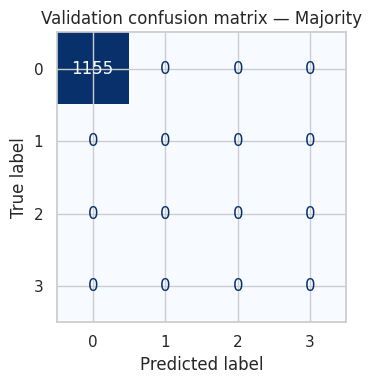


 Persistence


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,Persistence,1.0,0.25,1.0,0,0.0


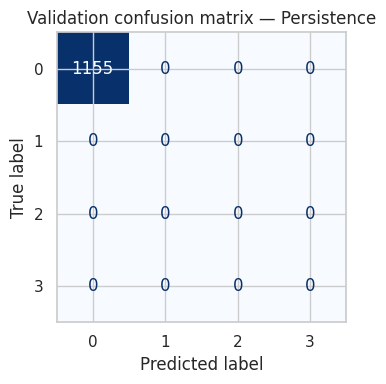


 Random forest


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,Random forest,1.0,0.25,1.0,150,2.2056


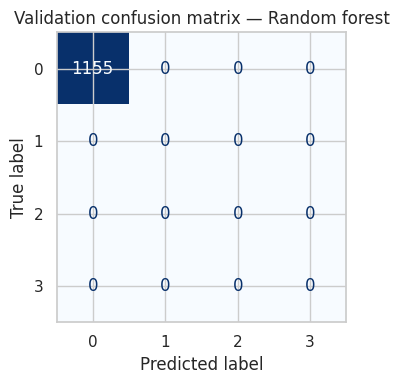

{'Model': 'Random forest',
 'Accuracy': 1.0,
 'Macro F1': 0.25,
 'Balanced accuracy': np.float64(1.0),
 'Parameters / trees': 150,
 'Train seconds': 2.2055770329999973}

In [17]:
from sklearn.metrics import accuracy_score,f1_score,balanced_accuracy_score,confusion_matrix,ConfusionMatrixDisplay
from sklearn.ensemble import RandomForestClassifier
from collections import Counter

results=[]
def evaluate_validation(name,pred,fit_seconds=0.0,params=0):
    row={'Model':name,'Accuracy':accuracy_score(y_val,pred),
         'Macro F1':f1_score(y_val,pred,labels=all_classes,average='macro',zero_division=0),
         'Balanced accuracy':balanced_accuracy_score(y_val,pred),
         'Parameters / trees':params,'Train seconds':fit_seconds}
    results.append(row)
    print('\n',name);display(pd.DataFrame([row]).round(4))
    cm=confusion_matrix(y_val,pred,labels=all_classes)
    fig,ax=plt.subplots(figsize=(5,4))
    ConfusionMatrixDisplay(cm,display_labels=all_classes).plot(ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(f'Validation confusion matrix — {name}')
    plt.tight_layout();plt.show()
    return row

majority_label=Counter(y_train).most_common(1)[0][0]
majority_val=np.full(len(y_val),majority_label,dtype=int)
evaluate_validation('Majority',majority_val)
evaluate_validation('Persistence',persist_val)

start=time.perf_counter()
forest=RandomForestClassifier(n_estimators=150,max_depth=12,min_samples_leaf=3,
                             random_state=SEED,n_jobs=-1)
forest.fit(X_train.reshape(len(X_train),-1),y_train)
forest_time=time.perf_counter()-start
rf_val=forest.predict(X_val.reshape(len(X_val),-1))
evaluate_validation('Random forest',rf_val,forest_time,params=forest.n_estimators)

## 8. MLP and CNN — Lecture 3 + Lab 3 + Lecture 4

 For multiclass occupancy classification we use **softmax + sparse categorical cross entropy**

 MLP was implemented using Keras' sequential API

Input (20 timesteps x 20 features )

Flatten 400 values to a vector

Dense -32 neurons, RELu (for nonlinearity)

Dropout regularization 20% (to reduce dependence on hidden units and prevent overfitting)

Dense-4, Softmax for caltegorical output.

Total trainable parameters: 12964

- **MLP:** `Flatten` the time window, then `Dense` + ReLU.
- **CNN:** `Conv1D` slides filters along time, then pools local responses.
- **Both:** same X and y windows, 20 epochs maximum, early stopping and validation-only selection.


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │        12,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,964 (50.64 KB)

 Trainable params: 12,964 (50.64 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 101ms/step - accuracy: 0.5694 - loss: 1.0882 - val_accuracy: 1.0000 - val_loss: 0.0096
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8606 - loss: 0.3776 - val_accuracy: 1.0000 - val_loss: 0.0034
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8964 - loss: 0.2739 - val_accuracy: 1.0000 - val_loss: 0.0028
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9418 - loss: 0.1908 - val_accuracy: 1.0000 - val_loss: 0.0026
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9454 - loss: 0.1651 - val_accuracy: 1.0000 - val_loss: 0.0023
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9589 - loss: 0.1432 - val_accuracy: 1.0000 - val_loss: 0.0020
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9663 - loss: 0.1201 - val_accuracy: 1.0000 - val_loss: 0.0017
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9677 - loss: 0.1129 - val_accuracy: 1.0000 - val_los

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,MLP,1.0,0.25,1.0,12964,8.0567


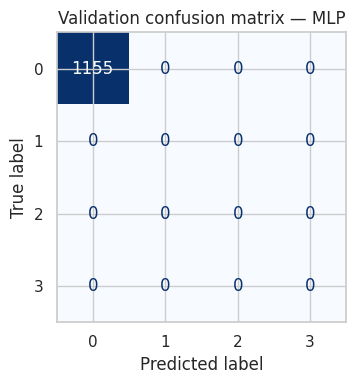

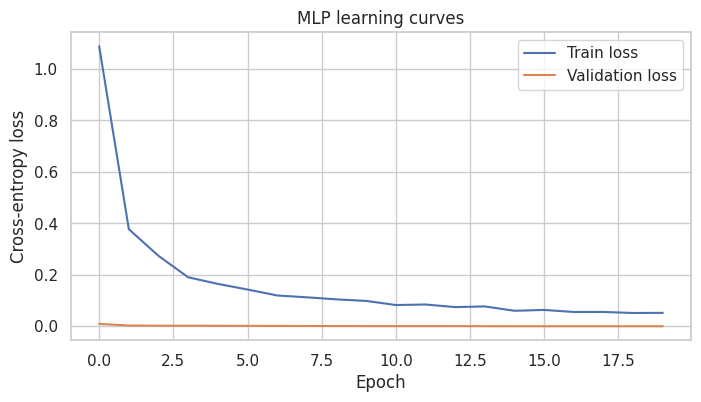

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 20, 32)         │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 10, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 10, 32)         │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │           132 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,188 (20.27 KB)

 Trainable params: 5,188 (20.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 6s 113ms/step - accuracy: 0.6492 - loss: 1.1552 - val_accuracy: 1.0000 - val_loss: 0.3052
Epoch 2/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7882 - loss: 0.5971 - val_accuracy: 1.0000 - val_loss: 0.0477
Epoch 3/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8702 - loss: 0.4167 - val_accuracy: 1.0000 - val_loss: 0.0219
Epoch 4/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9432 - loss: 0.3174 - val_accuracy: 1.0000 - val_loss: 0.0191
Epoch 5/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9652 - loss: 0.2451 - val_accuracy: 1.0000 - val_loss: 0.0154
Epoch 6/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9645 - loss: 0.1936 - val_accuracy: 1.0000 - val_loss: 0.0117
Epoch 7/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9741 - loss: 0.1575 - val_accuracy: 1.0000 - val_loss: 0.0096
Epoch 8/20
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9769 - loss: 0.1310 - val_accuracy: 1.0000 - val_los

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,CNN,1.0,0.25,1.0,5188,9.6301


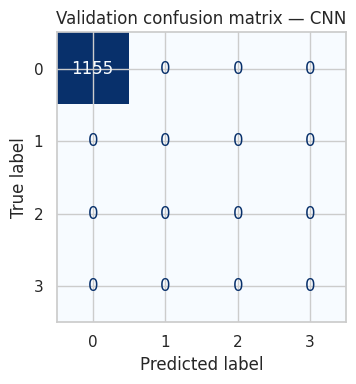

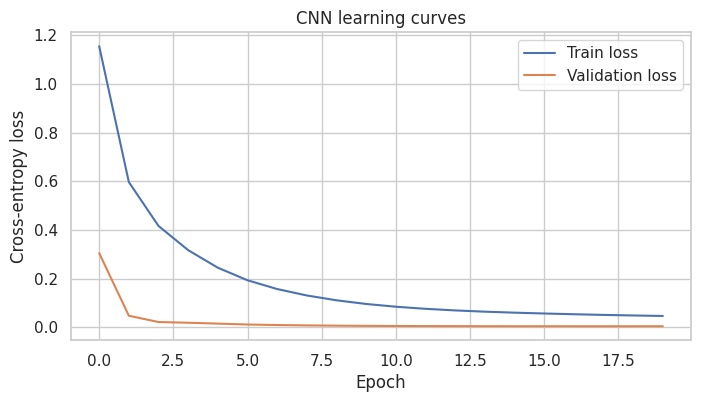

In [18]:
# B5. MLP and CNN: Sequential API (adapted from Lab 3)
import tensorflow as tf
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Dense, Flatten, Dropout, Conv1D, MaxPooling1D
from tensorflow.keras.layers import GlobalAveragePooling1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

tf.keras.utils.set_random_seed(SEED)
classes = np.array(all_classes)
class_to_idx = {value: i for i, value in enumerate(classes)}
y_train_idx = np.array([class_to_idx[value] for value in y_train])
y_val_idx = np.array([class_to_idx[value] for value in y_val])
n_classes = len(classes)

EPOCHS = 20
BATCH_SIZE = 128

def build_mlp(units=32, lr=0.001):
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        Flatten(),
        Dense(units, activation='relu'),
        Dropout(0.2),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def build_cnn(filters=32, kernel_size=3, lr=0.001):
    model = Sequential([
        Input(shape=X_train.shape[1:]),
        Conv1D(filters=filters, kernel_size=kernel_size,
               padding='causal', activation='relu'),
        MaxPooling1D(pool_size=2),
        Conv1D(filters=filters, kernel_size=kernel_size,
               padding='causal', activation='relu'),
        GlobalAveragePooling1D(),
        Dense(n_classes, activation='softmax')
    ])
    model.compile(optimizer=Adam(learning_rate=lr),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

def fit_and_predict(model, epochs=EPOCHS):
    early_stop = EarlyStopping(monitor='val_loss', patience=4,
                               restore_best_weights=True)
    start = time.perf_counter()
    history = model.fit(X_train, y_train_idx,
                        validation_data=(X_val, y_val_idx),
                        epochs=epochs, batch_size=BATCH_SIZE,
                        shuffle=False, callbacks=[early_stop], verbose=1)
    elapsed = time.perf_counter() - start
    prediction = model.predict(X_val, verbose=0).argmax(axis=1)
    prediction = classes[prediction]
    return history, prediction, elapsed

models = {}
histories = {}
if RUN_DEEP_MODELS:
    for model_name, builder in [('MLP', build_mlp), ('CNN', build_cnn)]:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = builder()
        model.summary()
        history, pred, seconds = fit_and_predict(model)
        models[model_name] = model
        histories[model_name] = history
        evaluate_validation(model_name, pred, seconds, model.count_params())

        plt.figure(figsize=(8, 4))
        plt.plot(history.history['loss'], label='Train loss')
        plt.plot(history.history['val_loss'], label='Validation loss')
        plt.xlabel('Epoch'); plt.ylabel('Cross-entropy loss')
        plt.title(model_name + ' learning curves')
        plt.legend(); plt.show()
else:
    print('Neural models skipped. Change RUN_DEEP_MODELS to True to run.')


Training lods show increasing training accuracy and decreasing training loss which is evidence of optimization to the training objective.

## 9. Small grid search — Lab 3 Section 4 style

 grid-search  uses `itertools.product`, a concise candidate table, and selects hyperparameters from **validation** only. We apply the same pattern to the CNN, using filters `[16, 32]` and learning rates `[0.01, 0.001]` (four trials). Our primary objective is **macro-F1**, appropriate for unequal occupancy class frequencies.




Input (20 timestamps x 20 features )

Conv1D - 32 filters, kernel size 3

Maxpooling1D - pool size 2 ( reduces sequence length from 20 to 10 )

Conv1D - 32 filters, kernel size 3

GlobalAveragePooling 1D (summarizes learned feature maps )

Dense - 4 , softmax

Total trainable parameters 5188

This is smaller than the MLP because convolution layers reuse filter weights instead of learning separate dense connections.

Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 111ms/step - accuracy: 0.6602 - loss: 0.8545 - val_accuracy: 1.0000 - val_loss: 2.7998e-04
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7524 - loss: 0.4198 - val_accuracy: 1.0000 - val_loss: 0.0029
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8265 - loss: 0.2500 - val_accuracy: 1.0000 - val_loss: 0.0090
Epoch 4/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.8861 - loss: 0.1944 - val_accuracy: 1.0000 - val_loss: 7.7496e-04
Epoch 5/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9635 - loss: 0.1453 - val_accuracy: 1.0000 - val_loss: 0.0058
Epoch 1/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.4612 - loss: 1.3258 - val_accuracy: 1.0000 - val_loss: 0.9401
Epoch 2/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.6658 - loss: 0.9146 - val_accuracy: 1.0000 - val_loss: 0.4119
Epoch 3/15
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7425 - loss: 0.7088 - val_accuracy: 1.0000 

,filters,learning_rate,validation_macro_f1,epochs,parameters,training_seconds
0,16,0.010,0.25,5,1828,5.9001
1,16,0.001,0.25,15,1828,6.1202
2,32,0.010,0.25,8,5188,4.8385
3,32,0.001,0.25,15,5188,6.4525


Best grid-search configuration: {'filters': 16, 'lr': 0.01}

 CNN (grid selected)


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:407: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds
0,CNN (grid selected),1.0,0.25,1.0,1828,5.9001


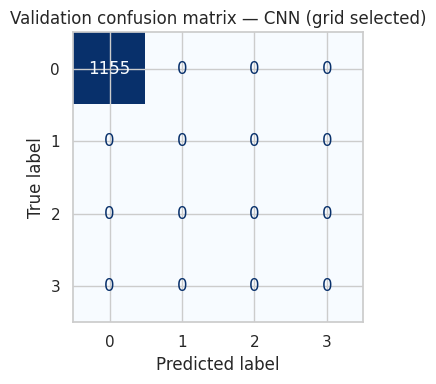

In [19]:
# B6. Small grid search — itertools.product
from itertools import product

grid = {'filters': [16, 32], 'lr': [0.01, 0.001]}
grid_results = []
best_grid_model = None
best_grid_score = -1
best_grid_config = None

if RUN_DEEP_MODELS and RUN_GRID_SEARCH:
    for filters, lr in product(grid['filters'], grid['lr']):
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        model = build_cnn(filters=filters, lr=lr)
        history, pred, elapsed = fit_and_predict(model, epochs=15)
        macro_f1 = f1_score(y_val, pred, labels=all_classes,
                            average='macro', zero_division=0)
        grid_results.append({'filters': filters, 'learning_rate': lr,
                             'validation_macro_f1': macro_f1,
                             'epochs': len(history.history['loss']),
                             'parameters': model.count_params(),
                             'training_seconds': elapsed})
        if macro_f1 > best_grid_score:
            best_grid_score = macro_f1
            best_grid_config = {'filters': filters, 'lr': lr}
            best_grid_model = model

    grid_table = pd.DataFrame(grid_results).sort_values(
        'validation_macro_f1', ascending=False)
    display(grid_table.round(4))
    print('Best grid-search configuration:', best_grid_config)
    best_pred = classes[best_grid_model.predict(X_val, verbose=0).argmax(axis=1)]
    selected = grid_table.iloc[0]
    evaluate_validation('CNN (grid selected)', best_pred,
                        float(selected['training_seconds']), best_grid_model.count_params())
else:
    print('Grid search skipped by configuration.')


Using the same training and validation windows, the MLp flattens the time-series input and learns relationships through fully connected layers , while the CNN uses convolutional filters to identify local temporal patterns.



## 10. Stage 1 comparison, result interpretation and risks
All reported metrics below use the same validation target timestamps. Report improvement relative to majority macro-F1. A **negative improvement** means worse than majority. Class-imbalance handling and the very short coverage are unresolved risks until tested.

In [20]:
comparison = pd.DataFrame(results).drop_duplicates(subset='Model',keep='last')
base = float(comparison.loc[comparison['Model']=='Majority','Macro F1'].iloc[0])
comparison['Macro F1 gain vs majority (%)'] = 100*(comparison['Macro F1']-base)/base if base else np.nan
comparison = comparison.sort_values('Macro F1',ascending=False)
display(comparison.round(4))
print('Best validation model:',comparison.iloc[0]['Model'])
print('UNRESOLVED RISK: class imbalance, short recording coverage, missing classes or occupancy drift by time segment.')

,Model,Accuracy,Macro F1,Balanced accuracy,Parameters / trees,Train seconds,Macro F1 gain vs majority (%)
0,Majority,1.0,0.25,1.0,0,0.0000,0.0
1,Persistence,1.0,0.25,1.0,0,0.0000,0.0
2,Random forest,1.0,0.25,1.0,150,2.2056,0.0
3,MLP,1.0,0.25,1.0,12964,8.0567,0.0
4,CNN,1.0,0.25,1.0,5188,9.6301,0.0
5,CNN (grid selected),1.0,0.25,1.0,1828,5.9001,0.0


Best validation model: Majority
UNRESOLVED RISK: class imbalance, short recording coverage, missing classes or occupancy drift by time segment.


In [22]:
# Local/Colab dependency report for the README/requirements file.
import sklearn, tensorflow
print('pandas=='+pd.__version__)
print('numpy=='+np.__version__)
print('matplotlib=='+plt.matplotlib.__version__)
print('seaborn=='+sns.__version__)
print('scikit-learn=='+sklearn.__version__)
print('tensorflow=='+tensorflow.__version__)
print('Seed:',SEED,'lookback:',LOOKBACK,'horizon:',HORIZON)

pandas==2.2.3
numpy==2.1.3
matplotlib==3.10.0
seaborn==0.13.2
scikit-learn==1.6.1
tensorflow==2.21.0
Seed: 42 lookback: 20 horizon: 2
